<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/04_nlp/03_named_entity_recognition_masakhaner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏷️ Application · Named Entity Recognition: who, where and when in Swahili news?

> *"Rais Samia Suluhu Hassan aliwasili Dodoma Jumatatu."*
> → **[PER** Samia Suluhu Hassan**]** arrived in **[LOC** Dodoma**]** on **[DATE** Monday**]**.

**Named Entity Recognition (NER)** finds the *names* in a text: persons, organisations, locations, dates… It powers
search engines, news monitoring, anonymisation of medical records, and the "extract the key facts" step of many
document-processing pipelines.

**A little history.** The term *named entity* was coined in **1995** at the 6th *Message Understanding Conference*
(MUC-6), a US competition to extract facts from news. In **2003** the *CoNLL* shared task made English and German NER
a standard benchmark. For African languages there was almost nothing until **Masakhane** volunteers annotated
**MasakhaNER** (2021, 10 languages), then **MasakhaNER 2.0** (2022, 20 languages, the largest NER dataset for
African languages). We use its Swahili part.

| Step | Concept |
|---|---|
| 1. Data | sentences, tokens and **BIO tags** |
| 2. The right metric | **entity-level F1** (seqeval), not token accuracy |
| 3. Baselines | memorisation, then a classic feature-based model |
| 4. Sub-word alignment | the tricky part of NER with transformers |
| 5. Fine-tuning | token classification with AfroXLMR |
| 6. Analysis & demo | per-entity scores, tag your own sentences |

⏱️ ~5 minutes on a laptop GPU.

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "seqeval", "sentencepiece"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

quest("Who, where and when?", chapter="Track 4 · NLP · Named entity recognition", xp=250)
DEVICE = get_device()

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Who, where and when?
   Track 4 · NLP · Named entity recognition
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


⚙️  Using device: mps  (Apple Silicon GPU (Metal))


## 1. Sentences, tokens and BIO tags 📥

Each example is a sentence already split into words (`tokens`) with one tag per word. Tags follow the **BIO**
scheme (Ramshaw & Marcus, 1995):
- `B-XXX` = **B**eginning of an entity of type XXX,
- `I-XXX` = **I**nside the same entity (continuation),
- `O` = **O**utside any entity.

So *"Samia Suluhu Hassan"* is `B-PER I-PER I-PER`. The B/I distinction lets us separate two entities that touch.

In [3]:
LANG = "swa"   # also available: yor, hau, ibo, kin, lug, luo, pcm, wol, zul, xho, twi, fon, bam, ewe, mos, nya, sna, tsn, bbj
TAGS = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-DATE", "I-DATE"]

def load(split):
    d = hf_parquet("masakhane/masakhaner2", split, config=LANG)
    return [(list(t), [TAGS[i] for i in g]) for t, g in zip(d["tokens"], d["ner_tags"])]

train, valid, test = load("train"), load("validation"), load("test")
print(f"{len(train)} train / {len(valid)} validation / {len(test)} test sentences")

tokens, tags = train[0]
pd.DataFrame({"token": tokens, "tag": tags}).T

6593 train / 942 validation / 1883 test sentences


,0,1,2,3,4,5,6,7,8,9,...,39,40,41,42,43,44,45,46,47,48
token,Maafisa,wa,serikali,ya,Yemen,wamesema,kuwa,tangu,Alhamisi,",",...,yaliofanywa,na,ushirika,wa,kijeshi,unaongozwa,na,Saudi,Arabia,.
tag,O,O,O,O,B-LOC,O,O,O,B-DATE,O,...,O,O,O,O,O,O,O,B-LOC,I-LOC,O


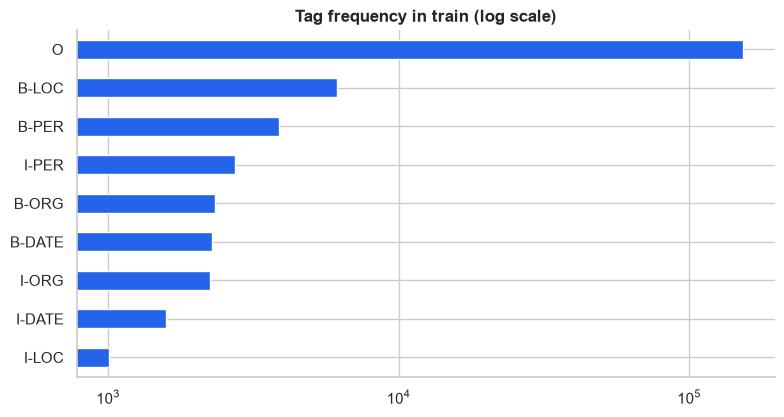

Share of 'O' tags: 87.4%


In [4]:
tag_counts = Counter(t for _, ts in train for t in ts)
pd.Series(tag_counts).sort_values().plot.barh(title="Tag frequency in train (log scale)", logx=True)
plt.show()
print(f"Share of 'O' tags: {tag_counts['O'] / sum(tag_counts.values()):.1%}")

## 2. The right metric 🎯

Since ~85% of tokens are `O`, a model that predicts `O` everywhere gets ~85% **token accuracy** while finding zero
entities. Useless! NER is evaluated at the **entity level** with the `seqeval` library: an entity counts as correct
only if its **type and exact boundaries** are right. Precision = correct / predicted entities, recall = correct /
true entities, F1 = their harmonic mean. This is the official MasakhaNER metric.

In [5]:
from seqeval.metrics import f1_score, classification_report

y_valid = [ts for _, ts in valid]
all_o = [["O"] * len(ts) for ts in y_valid]
token_acc = np.mean([p == t for ps, ts in zip(all_o, y_valid) for p, t in zip(ps, ts)])
print(f"'Always O' → token accuracy {token_acc:.1%}, entity F1 {f1_score(y_valid, all_o):.3f}")

lb = Leaderboard("masakhaner_swa", metric="entity_F1")

'Always O' → token accuracy 87.6%, entity F1 0.000


## 3. Baselines 🧱

**Baseline 1, the parrot.** For each word, predict the tag it had most often in the training set (unknown words
→ `O`). It measures how much NER is just *memorising names*.

In [6]:
memory = defaultdict(Counter)
for toks, ts in train:
    for tok, t in zip(toks, ts):
        memory[tok][t] += 1

def parrot(toks):
    return [memory[t].most_common(1)[0][0] if t in memory else "O" for t in toks]

lb.add("Parrot (memorise each word's tag)", f1_score(y_valid, [parrot(t) for t, _ in valid]))

📋 Parrot (memorise each word's tag): entity_F1 = 0.64197


**Baseline 2, the 2000s way: hand-crafted features + a linear model.** Before deep learning, NER systems described
each word with clues: is it capitalised? its suffix? the previous and next words? Then a classifier (often a *CRF*)
predicted the tag. We use a logistic regression on such features.

In [7]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

def word_features(toks, i):
    w = toks[i]
    f = {"w": w.lower(), "suffix3": w[-3:].lower(), "prefix3": w[:3].lower(),
         "is_title": w.istitle(), "is_upper": w.isupper(), "is_digit": w.isdigit(), "len": min(len(w), 12)}
    for off in (-2, -1, 1, 2):                      # context window: neighbours often reveal the type
        j = i + off
        f[f"w{off:+d}"] = toks[j].lower() if 0 <= j < len(toks) else "<pad>"
        f[f"title{off:+d}"] = toks[j].istitle() if 0 <= j < len(toks) else False
    return f

def featurize(data):
    return [word_features(toks, i) for toks, _ in data for i in range(len(toks))], [t for _, ts in data for t in ts]

Xtr, ytr = featurize(train)
vec = DictVectorizer()
clf = LogisticRegression(max_iter=1000, C=2).fit(vec.fit_transform(Xtr), ytr)

def predict_features(data):
    flat = clf.predict(vec.transform(featurize(data)[0]))
    out, k = [], 0
    for toks, _ in data:
        out.append(list(flat[k:k + len(toks)])); k += len(toks)
    return out

lb.add("Features + LogReg (2000s style)", f1_score(y_valid, predict_features(valid)))
lb.show()

📋 Features + LogReg (2000s style): entity_F1 = 0.82637  👑 new best!


,,model,entity_F1
rank,,,
1,🥇,Features + LogReg (2000s style),0.82637
2,🥈,Parrot (memorise each word's tag),0.64197


In [8]:
checkpoint("masakhaner/baselines", xp=40)

✅ Checkpoint · masakhaner/baselines (+40 XP)
   █████████░░░░░░░░░░░░░░░ 40/100 XP


## 4. The tricky part: aligning tags with sub-words ✂️

A transformer tokenizer cuts words into sub-words: one word → several tokens. But we have **one tag per word**.
The standard solution:
- give the word's tag to its **first** sub-token,
- give the special label `-100` to the other sub-tokens and to special tokens (`<s>`, `</s>`): PyTorch's loss
  **ignores** -100, so they don't count.

`word_ids()` tells us which word each sub-token comes from.

In [9]:
import logging
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
import transformers
from transformers import AutoTokenizer, AutoModelForTokenClassification, TrainingArguments, Trainer, DataCollatorForTokenClassification
transformers.logging.set_verbosity_error()          # keep the notebook readable (hide loading reports)
transformers.utils.logging.disable_progress_bar()
from datasets.utils.logging import disable_progress_bar
disable_progress_bar()

MODEL_NAME = "Davlan/afro-xlmr-mini"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tag2id = {t: i for i, t in enumerate(TAGS)}

def encode(toks, ts):
    enc = tokenizer(toks, is_split_into_words=True, truncation=True, max_length=128)
    labels, prev = [], None
    for wid in enc.word_ids():
        labels.append(-100 if wid is None or wid == prev else tag2id[ts[wid]])
        prev = wid
    enc["labels"] = labels
    return enc

toks, ts = train[0]
enc = encode(toks, ts)
pd.DataFrame({"sub-token": tokenizer.convert_ids_to_tokens(enc["input_ids"]), "word_id": enc.word_ids(),
              "label": [TAGS[l] if l != -100 else "-100 (ignored)" for l in enc["labels"]]}).head(16).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
sub-token,<s>,▁Maaf,isa,▁wa,▁serikali,▁ya,▁Yemen,▁wa,mesema,▁kuwa,▁tangu,▁Alhamisi,▁,",",▁Wah,u
word_id,NaN,0.0,0.0,1.0,2.0,3.0,4.0,5.0,5.0,6.0,7.0,8.0,9.0,9.0,10.0,10.0
label,-100 (ignored),O,-100 (ignored),O,O,O,B-LOC,O,-100 (ignored),O,O,B-DATE,O,-100 (ignored),O,-100 (ignored)


## 5. Fine-tuning for token classification 🔥

Same transfer-learning recipe as for text classification, except the head predicts a tag for **every** token.

In [10]:
from datasets import Dataset

def to_dataset(data):
    rows = [dict(encode(toks, ts)) for toks, ts in data]
    return Dataset.from_list(rows)

train_ds, valid_ds, test_ds = to_dataset(train), to_dataset(valid), to_dataset(test)

model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME, num_labels=len(TAGS), id2label=dict(enumerate(TAGS)), label2id=tag2id)

def align_predictions(logits, labels):
    preds = logits.argmax(-1)
    y_true, y_pred = [], []
    for p_row, l_row in zip(preds, labels):
        keep = l_row != -100
        y_true.append([TAGS[l] for l in l_row[keep]])
        y_pred.append([TAGS[p] for p in p_row[keep]])
    return y_true, y_pred

def compute_metrics(eval_pred):
    y_true, y_pred = align_predictions(*eval_pred)
    return {"entity_f1": f1_score(y_true, y_pred)}

args = TrainingArguments(
    output_dir=str(RUNS_DIR / "masakhaner_afroxlmr"),
    num_train_epochs=4,
    learning_rate=1.5e-4,          # small models like a slightly larger learning rate
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    warmup_steps=50,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=100,
    report_to="none",
    dataloader_num_workers=NUM_WORKERS,
    dataloader_pin_memory=(DEVICE == "cuda"),
    seed=SEED,
)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=valid_ds,
                  processing_class=tokenizer, data_collator=DataCollatorForTokenClassification(tokenizer),
                  compute_metrics=compute_metrics)
trainer.train();

{'loss': '1.367', 'grad_norm': '0.926', 'learning_rate': '0.0001406', 'epoch': '0.4831'}


{'loss': '0.5711', 'grad_norm': '0.6138', 'learning_rate': '0.0001213', 'epoch': '0.9662'}


{'eval_loss': '0.3418', 'eval_entity_f1': '0.3772', 'eval_runtime': '3.469', 'eval_samples_per_second': '271.6', 'eval_steps_per_second': '4.325', 'epoch': '1'}


{'loss': '0.2773', 'grad_norm': '0.6263', 'learning_rate': '0.000102', 'epoch': '1.449'}


{'loss': '0.1868', 'grad_norm': '0.4987', 'learning_rate': '8.271e-05', 'epoch': '1.932'}


{'eval_loss': '0.1548', 'eval_entity_f1': '0.904', 'eval_runtime': '2.456', 'eval_samples_per_second': '383.6', 'eval_steps_per_second': '6.109', 'epoch': '2'}


... (2 outputs left out)

{'eval_loss': '0.1115', 'eval_entity_f1': '0.9141', 'eval_runtime': '2.91', 'eval_samples_per_second': '323.7', 'eval_steps_per_second': '5.154', 'epoch': '3'}


{'loss': '0.09203', 'grad_norm': '0.7424', 'learning_rate': '2.487e-05', 'epoch': '3.382'}


{'loss': '0.08248', 'grad_norm': '0.2463', 'learning_rate': '5.591e-06', 'epoch': '3.865'}


{'eval_loss': '0.09876', 'eval_entity_f1': '0.9251', 'eval_runtime': '2.203', 'eval_samples_per_second': '427.6', 'eval_steps_per_second': '6.809', 'epoch': '4'}
{'train_runtime': '290.5', 'train_samples_per_second': '90.8', 'train_steps_per_second': '2.851', 'train_loss': '0.3438', 'epoch': '4'}


In [11]:
lb.add("AfroXLMR-mini fine-tuned", trainer.evaluate()["eval_entity_f1"])
lb.show()

{'eval_loss': '0.09876', 'eval_entity_f1': '0.9251', 'eval_runtime': '2.324', 'eval_samples_per_second': '405.4', 'eval_steps_per_second': '6.455', 'epoch': '4'}
📋 AfroXLMR-mini fine-tuned: entity_F1 = 0.92511  👑 new best!


,,model,entity_F1
rank,,,
1,🥇,AfroXLMR-mini fine-tuned,0.92511
2,🥈,Features + LogReg (2000s style),0.82637
3,🥉,Parrot (memorise each word's tag),0.64197


In [12]:
checkpoint("masakhaner/transformer", xp=80)

✅ Checkpoint · masakhaner/transformer (+80 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ██░░░░░░░░░░░░░░░░░░░░░░ 120/300 XP


## 6. Analysis: which entities are hard? 🔬

In [13]:
out = trainer.predict(test_ds)
y_true, y_pred = align_predictions(out.predictions, out.label_ids)
print(f"🏁 Test entity F1: {f1_score(y_true, y_pred):.3f}\n")
print(classification_report(y_true, y_pred, digits=3))

🏁 Test entity F1: 0.914



              precision    recall  f1-score   support

        DATE      0.716     0.818     0.763       598
         LOC      0.952     0.949     0.951      1924
         ORG      0.803     0.922     0.858       628
         PER      0.963     0.971     0.967      1180

   micro avg      0.895     0.933     0.914      4330
   macro avg      0.859     0.915     0.885      4330
weighted avg      0.901     0.933     0.916      4330



**How to read it.** Persons and locations are found best: names are capitalised and appear in typical contexts
("*Rais* …", "*mkoani* …", "*nchini* …"). Organisations are harder: long, varied names, often confused with
locations (is "Simba" a club, an animal or a place? is "Tanzania" a country or part of "Benki Kuu ya Tanzania"?,
the Bank of Tanzania). Dates are the hardest: in Swahili
they mix words and numbers ("*mwezi Machi mwaka 2020*", "*mwaka huu*") and their boundaries are easy to get slightly
wrong, and one wrong boundary = one wrong entity.

## 7. 🎤 Tag your own sentences

In [14]:
from transformers import pipeline

ner = pipeline("token-classification", model=trainer.model, tokenizer=tokenizer,
               aggregation_strategy="first", device=DEVICE)

import warnings
warnings.filterwarnings("ignore", message="Tokenizer does not support real words")

def show_entities(text):
    out, last = "", 0
    for ent in ner(text):
        span = text[ent["start"]:ent["end"]]
        core = span.strip().rstrip(".,;:!?")              # words come with their punctuation: keep it outside
        out += text[last:ent["start"]] + f"[{ent['entity_group']}: {core}]" + span.strip()[len(core):]
        last = ent["end"]
    print("•", out + text[last:])

for s in ["Rais Samia Suluhu Hassan aliwasili Dodoma siku ya Jumatatu.",
          "Klabu ya Yanga itacheza na Simba jijini Dar es Salaam tarehe 5 Machi 2025.",
          "Benki Kuu ya Tanzania imetangaza riba mpya mwaka huu.",
          "Eliud Kipchoge alishinda mbio za Berlin nchini Ujerumani."]:
    show_entities(s)

• Rais [PER: Samia Suluhu Hassan] aliwasili [LOC: Dodoma] siku ya [DATE: Jumatatu].
• Klabu ya [ORG: Yanga] itacheza na [ORG: Simba] jijini [LOC: Dar es Salaam] tarehe [DATE: 5 Machi 2025].


• Benki [ORG: Kuu ya Tanzania] imetangaza riba mpya [DATE: mwaka huu].
• [PER: Eliud Kipchoge] alishinda mbio za [LOC: Berlin] nchini [LOC: Ujerumani].


## 🏆 Quest complete!

You trained a model that reads Swahili and extracts who, where and when, beating memorisation and a classic
feature-based system.

### 🚀 Your turn (bonus XP)
1. Change `LANG` to `"yor"` (Yoruba), `"hau"` (Hausa) or `"pcm"` (Nigerian Pidgin). Which language is hardest?
2. **Cross-lingual transfer**: train on Swahili, evaluate on Kinyarwanda (`"kin"`) or Luganda (`"lug"`) without
   any training data in that language. This is how NLP reaches low-resource languages.
3. Add the parrot's prediction as a feature to the logistic regression. Does it help?
4. Build an anonymiser: replace every `PER` entity by `<NAME>` in a paragraph.

In [15]:
checkpoint("masakhaner/complete", xp=130)
badge("Entity Spotter", "🏷️")
progress()

✅ Checkpoint · masakhaner/complete (+130 XP)
   ██████████████████░░░░░░ 250/300 XP
╔════════════════════════════════════╗
║ 🏷️  BADGE UNLOCKED: Entity Spotter ║
╚════════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 3
Badges: 🏷️ Entity Spotter
